# 09 — Расширенная сеть, учитель и RL

52 причинных признака; слои 96/128; метки планировщика только из train; затем Double DQN. Основная сеть сохранена. Test уже известен. Изменения локальные.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from stronger_agent import Network
# Полный повтор: python stronger_agent.py
# Здесь читаются готовые результаты.
display(pd.Series(json.loads(Path('results/stronger_agent/protocol.json').read_text())))
display(pd.read_csv('results/stronger_agent/screen.csv'))
display(pd.read_csv('results/stronger_agent/finalists.csv'))

inputs                                                             52
widths                                                      [96, 128]
learning_rates                                        [0.0003, 0.001]
imitation_epochs                                                   80
teacher_factors                     [0.5, 0.75, 1, 1.25, 1.5, 2, 2.5]
teacher             Perfect-future planner within TRAIN only, lexi...
refine_finalists                                                    2
refine_seeds                                             [7, 42, 123]
refine_episodes                                                   200
checkpoint                        5 imitation epochs / 20 RL episodes
selection           Mean validation lexicographic risk/excess/cost...
initial                                results/safety/m30_e10_s42.npz
initial_sha256      2b6e6b32dce3a3d2becffd9b1cb5486d0ecd29bc05372f...
comparison_note     More past routing information than old DQN; im...
test                

,trial,width,lr,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,0,96,0.0003,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
1,1,96,0.0010,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
2,2,128,0.0003,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
3,3,128,0.0010,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14


,name,trial,seed,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,trial_0_seed_7,0,7,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
1,trial_0_seed_42,0,42,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
2,trial_0_seed_123,0,123,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
3,trial_1_seed_7,1,7,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
4,trial_1_seed_42,1,42,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14
5,trial_1_seed_123,1,123,1203.797933,732.0,462.935848,8.862085,67,125201,45.831304,7.625,14


Учитель использует будущие события только внутри train для меток. Политика видит только прошлую нагрузку и текущее размещение. При ухудшении validation сохраняется исходная политика. Более низкий loss не гарантирует меньше перегрузки.

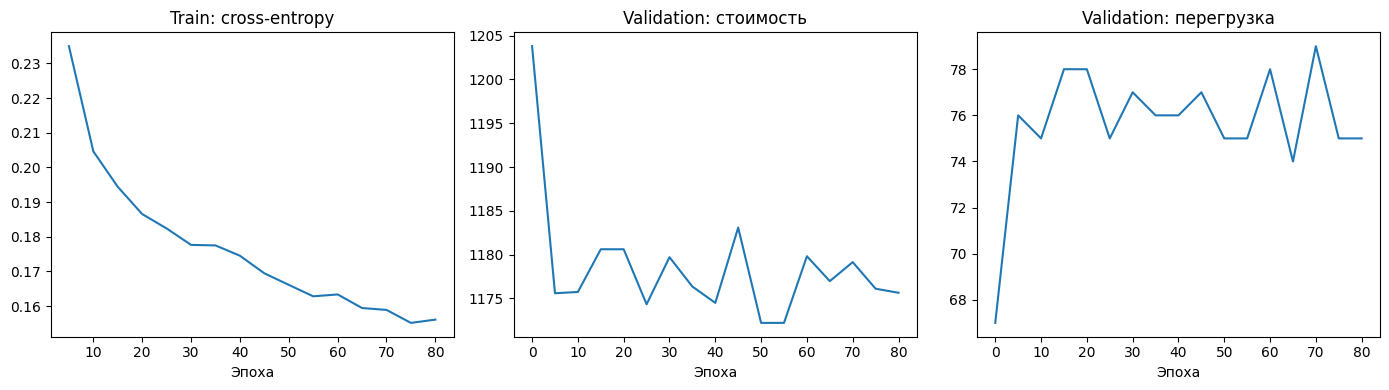

In [2]:
h=pd.read_csv('results/stronger_agent/screen_0_history.csv')
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col,title in zip(axes,['loss','cost','overloaded_slots'],['Train: cross-entropy','Validation: стоимость','Validation: перегрузка']):
    ax.plot(h.epoch,h[col]);ax.set(title=title,xlabel='Эпоха')
fig.tight_layout();fig.savefig('results/stronger_agent/training.png',dpi=150);plt.show()

In [3]:
display(pd.read_csv('results/stronger_agent/comparison_with_baseline.csv',index_col=0).round(3))
display(pd.read_csv('results/stronger_agent/test_seeds.csv'))
s=json.loads(Path('results/stronger_agent/selection.json').read_text())
net=Network.load(Path('results/stronger_agent')/(s['name']+'.npz'))
print('Параметров:',sum(p.size for p in net.p))
print('Выбранная версия повторяет исходную политику; новая основная модель не принята.')

,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
previous_safety,889.649,854.0,9.610,26.039,2.0,2599.0,134.664,4.448,31.0
stronger_agent,889.649,854.0,9.610,26.039,2.0,2599.0,134.664,4.448,31.0
causal_routing_baseline,868.467,809.0,18.669,40.798,4.0,5049.0,210.990,4.214,48.0


,seed,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,7,889.648951,854.0,9.609909,26.039042,2,2599,134.663934,4.447917,31
1,42,889.648951,854.0,9.609909,26.039042,2,2599,134.663934,4.447917,31
2,123,889.648951,854.0,9.609909,26.039042,2,2599,134.663934,4.447917,31


Параметров: 14691
Выбранная версия повторяет исходную политику; новая основная модель не принята.


Увеличение сети и более сложное обучение не улучшили результат без ухудшения перегрузки. Остаётся прежняя safety DQN. Одинаковые seed-результаты вызваны возвратом к общему исходному checkpoint, не независимым подтверждением новых моделей.